# Part 1: How temperature affects battery ageing

Lithium-ion cells age at different speeds depending on their temperature. Too warm and the SEI layer on the anode keeps growing. Too cold and lithium starts plating on the anode during charging. Somewhere in between, ageing is slowest.

This notebook reproduces that idea using the activation energies reported by Waldmann et al. (2014), who cycled commercial 18650 cells between −20 °C and 70 °C.

**Reference:** T. Waldmann, M. Wilka, M. Kasper, M. Fleischhammer, M. Wohlfahrt-Mehrens, *Temperature dependent ageing mechanisms in Lithium-ion batteries – A Post-Mortem study*, J. Power Sources 262 (2014) 129–135. [doi:10.1016/j.jpowsour.2014.03.112](https://doi.org/10.1016/j.jpowsour.2014.03.112)

## The model

Each ageing mechanism follows the Arrhenius law:

$$r = A \exp\left(-\frac{E_a}{k_B T}\right)$$

The paper found two regimes:

| Mechanism | Dominant range | $E_a$ |
|---|---|---|
| SEI growth, cathode degradation | above 25 °C | 0.38 eV |
| Lithium plating | below 25 °C | −0.57 eV (apparent) |

A negative activation energy just means the rate goes *up* as the temperature goes down.

To get one curve, I add the two mechanisms together and pick their weights so the minimum lands at 25 °C, where the paper saw the slowest ageing.

One honest caveat: the paper fitted two straight lines that meet in a sharp V. Adding the mechanisms gives a smoother curve with the same slopes, but it reads lower than the paper's fits far away from 25 °C. Use it to understand the trend, not to read off exact numbers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Inputs

In [2]:
K_B = 8.617e-5            # Boltzmann constant in eV/K

T_OPTIMUM_C = 25.0        # where the paper found the slowest ageing
EA_SEI = 0.38             # eV, SEI growth branch (hot side)
EA_PLATING = -0.57        # eV, lithium plating branch (cold side)

LOW_AGEING_FACTOR = 1.5   # shade the range where ageing is within 1.5x of the minimum

## Ageing rate vs. temperature

In [3]:
temp_c = np.linspace(-20, 70, 901)
temp_k = temp_c + 273.15
t_opt_k = T_OPTIMUM_C + 273.15

# Distance from the optimum on the Arrhenius axis (1/kT)
x = 1 / (K_B * temp_k) - 1 / (K_B * t_opt_k)

# At the minimum the two slopes cancel out, which fixes the ratio of the weights
weight_sei = abs(EA_PLATING)
weight_plating = EA_SEI

rate_sei = weight_sei * np.exp(-EA_SEI * x)
rate_plating = weight_plating * np.exp(-EA_PLATING * x)
rate_total = rate_sei + rate_plating

# Scale everything so the slowest ageing rate equals 1
scale = rate_total.min()
rate_sei /= scale
rate_plating /= scale
rate_total /= scale

In [4]:
low_ageing = temp_c[rate_total <= LOW_AGEING_FACTOR]

print(f"Slowest ageing at {temp_c[rate_total.argmin()]:.0f} °C")
print(f"Within {LOW_AGEING_FACTOR}x of that: {low_ageing.min():.0f} °C to {low_ageing.max():.0f} °C\n")

for t in (-20, 0, 25, 50, 70):
    print(f"{t:>4} °C  ->  {np.interp(t, temp_c, rate_total):4.1f}x the slowest rate")

Slowest ageing at 25 °C
Within 1.5x of that: 11 °C to 43 °C

 -20 °C  ->  20.7x the slowest rate
   0 °C  ->   3.2x the slowest rate
  25 °C  ->   1.0x the slowest rate
  50 °C  ->   2.0x the slowest rate
  70 °C  ->   4.2x the slowest rate


## Plot

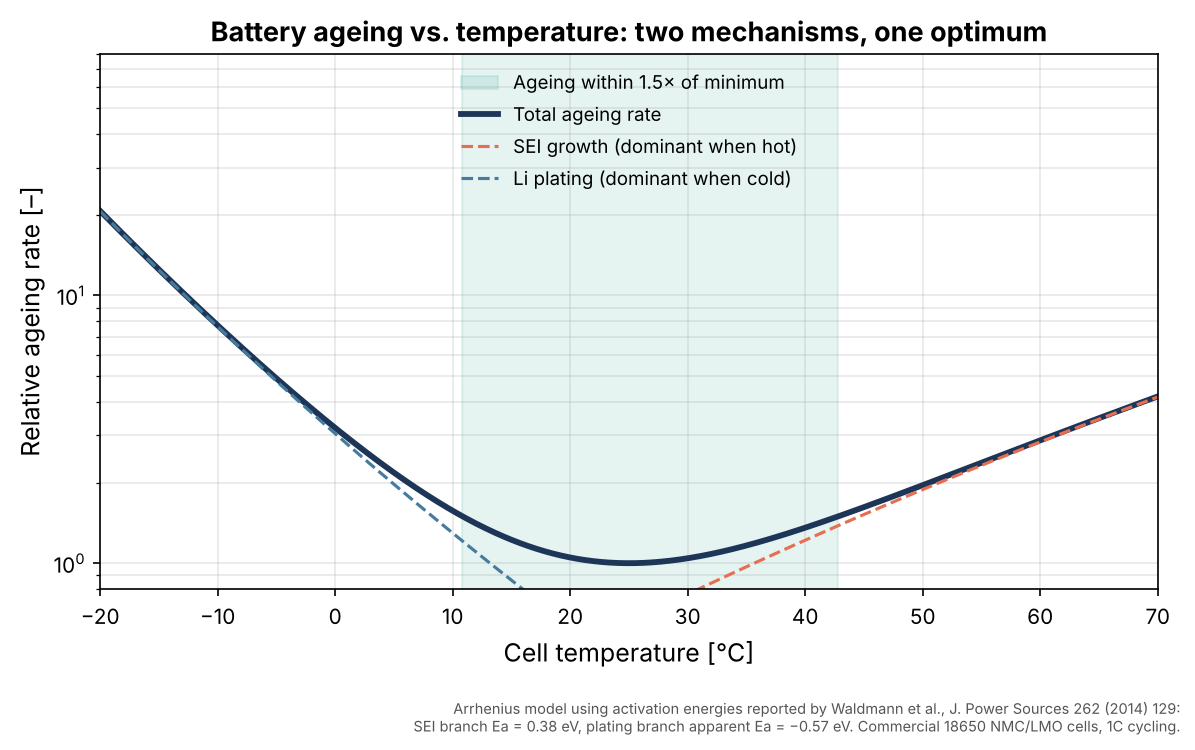

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.axvspan(low_ageing.min(), low_ageing.max(), color="#2a9d8f", alpha=0.12,
           label=f"Ageing within {LOW_AGEING_FACTOR}× of minimum")
ax.semilogy(temp_c, rate_total, color="#1d3557", lw=2.8, label="Total ageing rate")
ax.semilogy(temp_c, rate_sei, "--", color="#e76f51", lw=1.5, label="SEI growth (dominant when hot)")
ax.semilogy(temp_c, rate_plating, "--", color="#457b9d", lw=1.5, label="Li plating (dominant when cold)")

ax.set_xlim(-20, 70)
ax.set_ylim(0.8, 80)
ax.set_xlabel("Cell temperature [°C]", fontsize=12)
ax.set_ylabel("Relative ageing rate [–]", fontsize=12)
ax.set_title("Battery ageing vs. temperature: two mechanisms, one optimum", fontsize=13, weight="bold")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="upper center", fontsize=9, frameon=False)

fig.text(0.99, 0.01,
         "Arrhenius model using activation energies reported by Waldmann et al., J. Power Sources 262 (2014) 129:\n"
         "SEI branch Ea = 0.38 eV, plating branch apparent Ea = −0.57 eV. Commercial 18650 NMC/LMO cells, 1C cycling.",
         ha="right", va="bottom", fontsize=7, color="#555")

plt.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig("../figures/01_ageing_vs_temperature.png", dpi=200)
plt.show()

## What to take away

- There's a best temperature window, not just an upper limit. In this study it was centred on 25 °C.
- Cold is as much of a problem as heat, and in the paper the damage came mostly from **charging** in the cold.
- These numbers are for one cell type (NMC/LMO blend cathode, graphite anode, 1C). Other chemistries and C-rates shift the optimum, so treat this as a picture of the mechanism, not a design value.

Try changing `EA_SEI`, `EA_PLATING` or `T_OPTIMUM_C` above and see how the window moves.